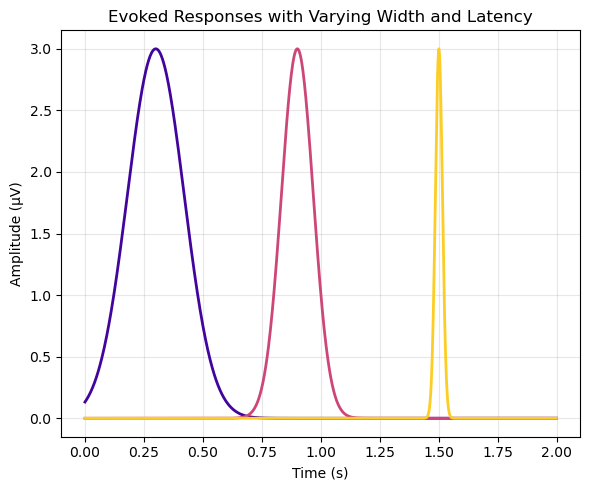

In [26]:
import numpy as np
import matplotlib.pyplot as plt

fs = 500
duration = 2.0
t = np.arange(0, duration, 1/fs)
amp = 3.0
n_erps = 3

# Wide+early → Narrow+late
sigmas = np.linspace(0.120, 0.015, n_erps)  # 120 ms → 15 ms
t0s    = np.linspace(0.3,   1.5,   n_erps)  # early → late

def make_erp(t, t0, sigma, amp):
    return amp * np.exp(-0.5 * ((t - t0) / sigma) ** 2)

erps = np.array([make_erp(t, t0, sigma, amp) for t0, sigma in zip(t0s, sigmas)])

# Plot time domain
colors = plt.cm.plasma(np.linspace(0.1, 0.9, n_erps))
fig, ax = plt.subplots(figsize=(6, 5))
for erp, t0, sigma, color in zip(erps, t0s, sigmas, colors):
    ax.plot(t, erp, lw=2, color=color, label=f'σ={sigma*1000:.0f}ms @ {t0*1000:.0f}ms')
ax.set_xlabel('Time (s)')
ax.set_ylabel('Amplitude (µV)')
ax.set_title('Evoked Responses with Varying Width and Latency')
# ax.legend(fontsize=8, framealpha=0.4)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

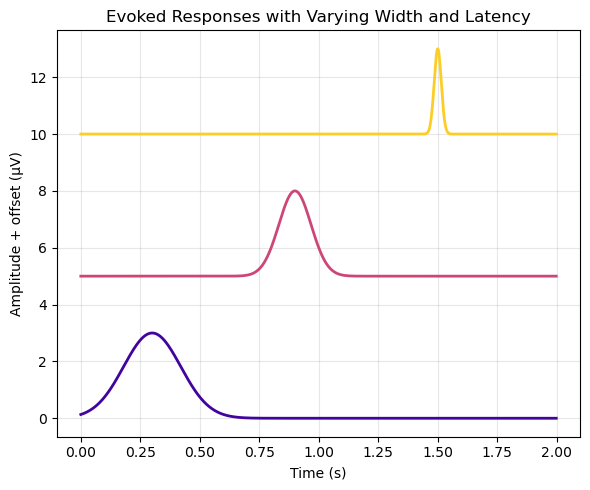

In [28]:
import numpy as np
import matplotlib.pyplot as plt

fs = 500
duration = 2.0
t = np.arange(0, duration, 1/fs)
amp = 3.0
n_erps = 3

# Wide+early → Narrow+late
sigmas = np.linspace(0.120, 0.015, n_erps)  # 120 ms → 15 ms
t0s    = np.linspace(0.3,   1.5,   n_erps)  # early → late

def make_erp(t, t0, sigma, amp):
    return amp * np.exp(-0.5 * ((t - t0) / sigma) ** 2)

erps = np.array([make_erp(t, t0, sigma, amp) for t0, sigma in zip(t0s, sigmas)])

# Plot time domain
colors = plt.cm.plasma(np.linspace(0.1, 0.9, n_erps))
fig, ax = plt.subplots(figsize=(6, 5))

offset = 5  # vertical spacing between trials

for i, (erp, t0, sigma, color) in enumerate(zip(erps, t0s, sigmas, colors)):
    ax.plot(t, erp + i * offset, lw=2, color=color,
            label=f'σ={sigma*1000:.0f}ms @ {t0*1000:.0f}ms')

ax.set_xlabel('Time (s)')
ax.set_ylabel('Amplitude + offset (µV)')
ax.set_title('Evoked Responses with Varying Width and Latency')
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

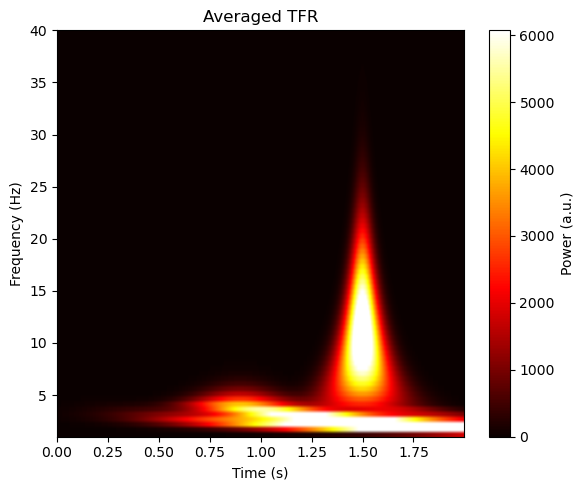

In [27]:
# Compute TFR for each ERP then average
freqs = np.linspace(1, 40, 80)
tfrs = np.zeros((len(erps), len(freqs), len(t)))

for i, erp in enumerate(erps):
    for fi, freq in enumerate(freqs):
        n_cycles = 6
        sigma_t = n_cycles / (2 * np.pi * freq)
        half_win = int(4 * sigma_t * fs)
        t_wav = np.arange(-half_win, half_win + 1) / fs
        wav = (1 / (sigma_t * np.sqrt(2 * np.pi))) \
              * np.exp(-t_wav**2 / (2 * sigma_t**2)) \
              * np.exp(2j * np.pi * freq * t_wav)
        conv = np.convolve(erp, wav, mode='same')
        tfrs[i, fi] = np.abs(conv[:len(t)]) ** 2

# Average across ERPs
tfr_avg = tfrs.mean(axis=0)

# Plot
fig, ax = plt.subplots(figsize=(6, 5))
im = ax.imshow(tfr_avg, aspect='auto', origin='lower',
               extent=[t[0], t[-1], freqs[0], freqs[-1]],
               cmap='hot', vmin=0, vmax=np.percentile(tfr_avg, 98))  # <-- raw power, no dB
plt.colorbar(im, ax=ax, label='Power (a.u.)')
ax.set_xlabel('Time (s)')
ax.set_ylabel('Frequency (Hz)')
ax.set_title('Averaged TFR')
plt.tight_layout()
plt.show()

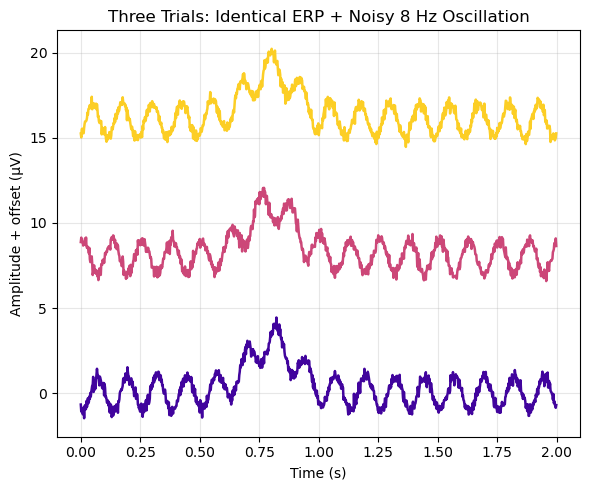

In [31]:
import numpy as np

import matplotlib.pyplot as plt

fs = 500

duration = 2.0

t = np.arange(0, duration, 1/fs)

n_trials = 3

amp = 3.0

# --- ERP (identical across trials) ---

t0 = 0.8

sigma = 0.1

def make_erp(t, t0, sigma, amp):

    return amp * np.exp(-0.5 * ((t - t0) / sigma) ** 2)

erp = make_erp(t, t0, sigma, amp)

# --- 8 Hz oscillation ---

freq = 8

osc_amp = 1.0

noise_level = 0.2

trials = []

for i in range(n_trials):

    phase = np.random.rand() * 2 * np.pi

    osc = osc_amp * np.sin(2 * np.pi * freq * t + phase)

    noise = noise_level * np.random.randn(len(t))

    trials.append(erp + osc + noise)

trials = np.array(trials)

# --- Plot trials stacked ---

colors = plt.cm.plasma(np.linspace(0.1, 0.9, n_trials))

offset = 8

fig, ax = plt.subplots(figsize=(6,5))

for i, (trial, color) in enumerate(zip(trials, colors)):

    ax.plot(t, trial + i*offset, lw=1.8, color=color)

ax.set_xlabel("Time (s)")

ax.set_ylabel("Amplitude + offset (µV)")

ax.set_title("Three Trials: Identical ERP + Noisy 8 Hz Oscillation")

ax.grid(alpha=0.3)

plt.tight_layout()

plt.show()

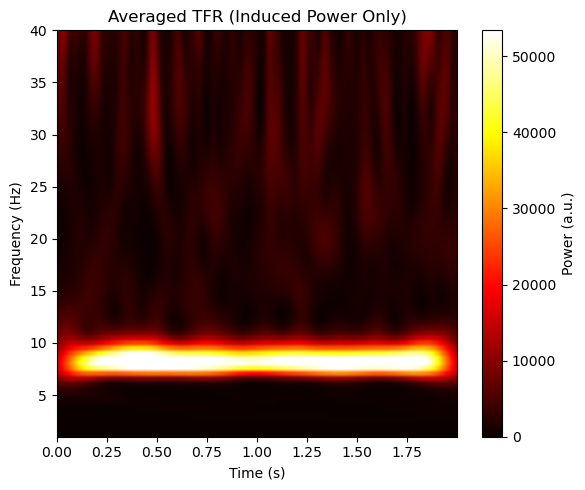

In [32]:
import numpy as np
import matplotlib.pyplot as plt

fs = 500
duration = 2.0
t = np.arange(0, duration, 1/fs)

# ----- simulate trials -----
n_trials = 3
amp = 3.0
t0 = 0.8
sigma = 0.06

def make_erp(t, t0, sigma, amp):
    return amp * np.exp(-0.5 * ((t - t0) / sigma) ** 2)

erp = make_erp(t, t0, sigma, amp)

freq = 8
osc_amp = 1.0
noise_level = 0.8

trials = []

for i in range(n_trials):
    phase = np.random.rand() * 2*np.pi
    osc = osc_amp * np.sin(2*np.pi*freq*t + phase)
    noise = noise_level * np.random.randn(len(t))
    trials.append(erp + osc + noise)

trials = np.array(trials)

# ----- regress ERP from each trial (keep induced activity) -----
trials_induced = np.zeros_like(trials)

for i, trial in enumerate(trials):
    beta = np.dot(trial, erp) / np.dot(erp, erp)
    trials_induced[i] = trial - beta * erp

# ----- compute TFR -----
freqs = np.linspace(1, 40, 80)
tfrs = np.zeros((len(trials_induced), len(freqs), len(t)))

for i, trial in enumerate(trials_induced):
    for fi, freq in enumerate(freqs):

        n_cycles = 6
        sigma_t = n_cycles / (2 * np.pi * freq)

        half_win = int(4 * sigma_t * fs)
        t_wav = np.arange(-half_win, half_win + 1) / fs

        wav = (1 / (sigma_t * np.sqrt(2 * np.pi))) \
            * np.exp(-t_wav**2 / (2 * sigma_t**2)) \
            * np.exp(2j * np.pi * freq * t_wav)

        conv = np.convolve(trial, wav, mode='same')

        tfrs[i, fi] = np.abs(conv[:len(t)]) ** 2

# average power across trials
tfr_avg = tfrs.mean(axis=0)

# ----- plot -----
fig, ax = plt.subplots(figsize=(6,5))

im = ax.imshow(
    tfr_avg,
    aspect='auto',
    origin='lower',
    extent=[t[0], t[-1], freqs[0], freqs[-1]],
    cmap='hot',
    vmin=0,
    vmax=np.percentile(tfr_avg, 98)
)

plt.colorbar(im, ax=ax, label='Power (a.u.)')

ax.set_xlabel('Time (s)')
ax.set_ylabel('Frequency (Hz)')
ax.set_title('Averaged TFR (Induced Power Only)')

plt.tight_layout()
plt.show()